# Mathematical Models of Metal Cutting

This notebook turns the formulas in the Sandvik Coromant *Metal Cutting Training Handbook* ("Formulas and definitions") into Python functions you can calculate with. Each section states the formulas, works one example, and then gives exercises. Every exercise has a `check()` cell that tells you whether your answer is within 1 percent of the reference value.

The functions live in the `metalcutting` package next to this notebook. Open the `.py` files to read the code; each function documents its symbols and units.

**Sections**

1. Symbols and units
2. Turning: speed, feed, chip thickness, specific cutting force, power, time, surface finish
3. Milling: table feed, chip thinning, power, torque
4. Drilling: penetration rate, power, torque, feed force
5. Tool life and machining economy (Taylor's equation)
6. Capstone: planning a two-operation part

All units are metric, following the handbook.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

from metalcutting import turning, milling, drilling, material, tool_life
from metalcutting.checks import check

# Plot style: thin lines, light grid
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
})
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

## 1. Symbols and units

| Symbol | Meaning | Unit |
|---|---|---|
| $v_c$ | cutting speed | m/min |
| $n$ | spindle speed | rpm |
| $D_m$, $D_{cap}$, $D_c$ | machined diameter (turning), cutting diameter at $a_p$ (milling), drill diameter | mm |
| $f_n$ | feed per revolution | mm/r |
| $f_z$ | feed per tooth | mm |
| $z_c$ | number of effective teeth | |
| $v_f$ | table feed or penetration rate | mm/min |
| $a_p$ | depth of cut | mm |
| $a_e$ | working engagement (radial width of cut) | mm |
| $\kappa_r$ | entering angle | degrees |
| $\gamma_0$ | rake angle | degrees |
| $h_{ex}$, $h_m$ | maximum and average chip thickness | mm |
| $k_{c1}$, $m_c$ | material constants for specific cutting force | N/mm², dimensionless |
| $k_c$ | specific cutting force | N/mm² |
| $P_c$ | net power | kW |
| $M_c$ | torque | Nm |
| $Q$ | metal removal rate | cm³/min |
| $T_c$ | machining time | min |
| $l_m$ | machined length | mm |

**Warm-up (E0).** The calculation behind every section is the link between cutting speed and spindle speed. Write your own function and test it on $D_m = 50$ mm, $v_c = 150$ m/min:

$$n = \frac{v_c \cdot 1000}{\pi \cdot D_m}$$

In [2]:
def my_spindle_speed(vc, Dm):
    ...  # your code here

E0 = ...  # your code here
check("E0", E0)

[ ] E0: not answered yet.


False

## 2. Turning

### 2.1 Speed, feed and removal rate

$$v_c = \frac{\pi \cdot D_m \cdot n}{1000} \qquad n = \frac{v_c \cdot 1000}{\pi \cdot D_m} \qquad v_f = f_n \cdot n \qquad Q = v_c \cdot a_p \cdot f_n$$

The cutting speed is set by the tool and material; the machine is programmed in rpm. Because $n$ depends on diameter, a lathe running at constant $v_c$ speeds up as the tool moves towards the centre.

### 2.2 Chip thickness and specific cutting force

The entering angle $\kappa_r$ spreads the feed over a longer edge, so the chip is thinner than the feed:

$$h_{ex} = f_n \cdot \sin\kappa_r$$

In turning the chip thickness is the same along the edge, so $h_m = h_{ex}$. The specific cutting force $k_c$ is the force needed to cut a chip of area 1 mm². Thin chips need more force per mm²:

$$k_c = k_{c1} \cdot h_m^{-m_c} \cdot \left(1 - \frac{\gamma_0}{100}\right)$$

$k_{c1}$ (the value at $h_m = 1$ mm) and $m_c$ come from the material table. A positive rake angle $\gamma_0$ lowers the force.

### 2.3 Power and time

$$P_c = \frac{v_c \cdot a_p \cdot f_n \cdot k_c}{60 \cdot 10^3}\ \text{kW} \qquad T_c = \frac{l_m}{f_n \cdot n}\ \text{min}$$

The $60 \cdot 10^3$ converts m/min to m/s and W to kW. The machine must deliver $P_c / \eta$ at the spindle, where $\eta$ is the drive efficiency.

In [3]:
# The material table used in this notebook (illustrative values, check them against the handbook)
for name, m in material.MATERIALS.items():
    print(f"{name:28s} kc1 = {m['kc1']:5d} N/mm^2   mc = {m['mc']}")

P1 unalloyed steel           kc1 =  1500 N/mm^2   mc = 0.25
P2 low-alloy steel           kc1 =  1700 N/mm^2   mc = 0.25
P3 high-alloy steel          kc1 =  2000 N/mm^2   mc = 0.25
M1 austenitic stainless      kc1 =  2000 N/mm^2   mc = 0.21
K1 grey cast iron            kc1 =  1100 N/mm^2   mc = 0.28
N1 aluminium alloy           kc1 =   500 N/mm^2   mc = 0.25
S1 nickel-based HRSA         kc1 =  2800 N/mm^2   mc = 0.25
H1 hardened steel            kc1 =  3000 N/mm^2   mc = 0.25


**Worked example.** Longitudinal turning of unalloyed steel (P1), $D_m = 100$ mm, $v_c = 200$ m/min, $f_n = 0.3$ mm/r, $a_p = 3$ mm, $\kappa_r = 95°$, $\gamma_0 = 6°$.

In [4]:
kc1, mc = material.get("P1 unalloyed steel")
Dm, vc, fn, ap, kr, gamma0 = 100, 200, 0.3, 3, 95, 6

n  = turning.spindle_speed(vc, Dm)
hm = turning.chip_thickness(fn, kr)
kc = material.specific_cutting_force(kc1, hm, mc, gamma0)
Q  = turning.metal_removal_rate(vc, ap, fn)
Pc = turning.net_power(vc, ap, fn, kc)

print(f"n  = {n:7.1f} rpm")
print(f"hm = {hm:7.3f} mm")
print(f"kc = {kc:7.0f} N/mm^2")
print(f"Q  = {Q:7.1f} cm^3/min")
print(f"Pc = {Pc:7.2f} kW")

n  =   636.6 rpm
hm =   0.299 mm
kc =    1907 N/mm^2
Q  =   180.0 cm^3/min
Pc =    5.72 kW


The curve below shows why chip thickness matters. Halving the chip thickness does not halve the force per mm²: $k_c$ rises steeply for thin chips.

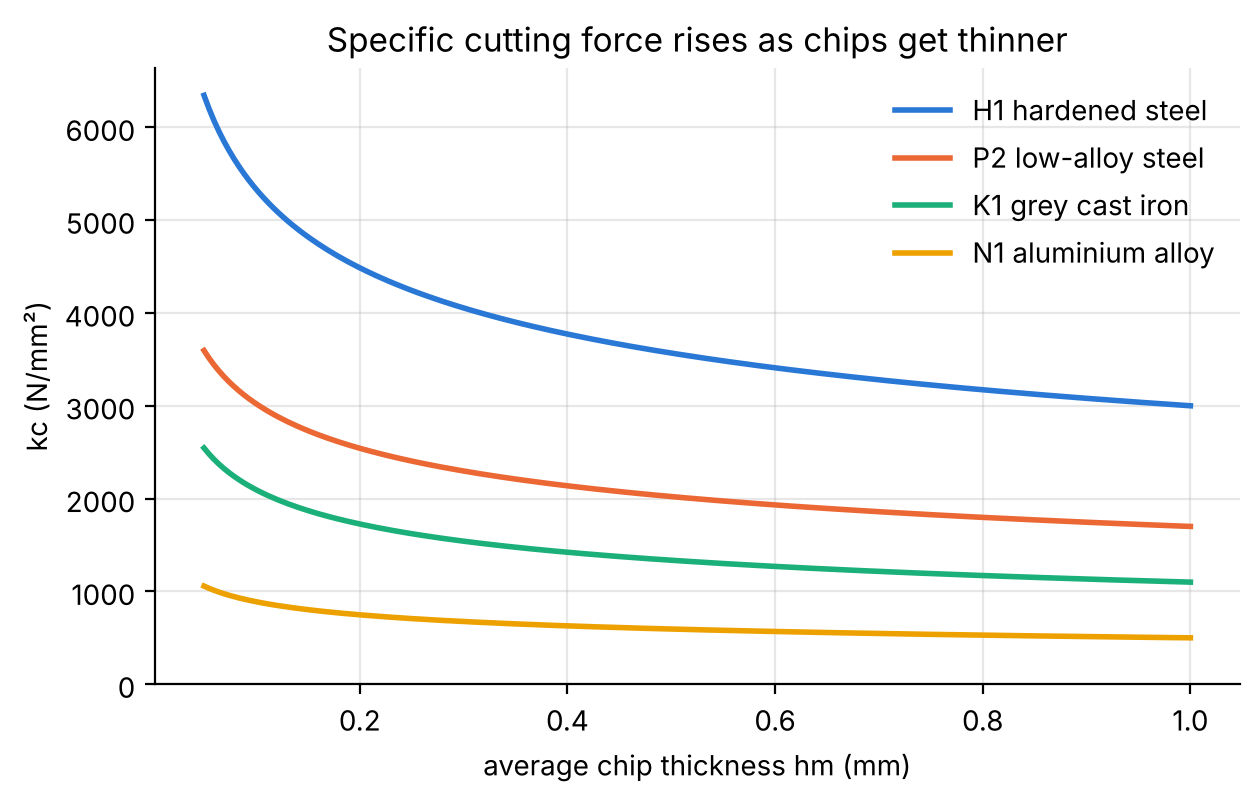

In [5]:
h = np.linspace(0.05, 1.0, 200)
fig, ax = plt.subplots()
for color, name in zip(COLORS, ["H1 hardened steel", "P2 low-alloy steel", "K1 grey cast iron", "N1 aluminium alloy"]):
    k1, m = material.get(name)
    ax.plot(h, [material.specific_cutting_force(k1, x, m) for x in h], color=color, label=name)
ax.set_xlabel("average chip thickness hm (mm)")
ax.set_ylabel("kc (N/mm²)")
ax.set_title("Specific cutting force rises as chips get thinner")
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
plt.show()

**Worked example (continued).** How does power grow with feed? Power is almost, but not quite, proportional to $f_n$, because $k_c$ falls as the chip gets thicker.

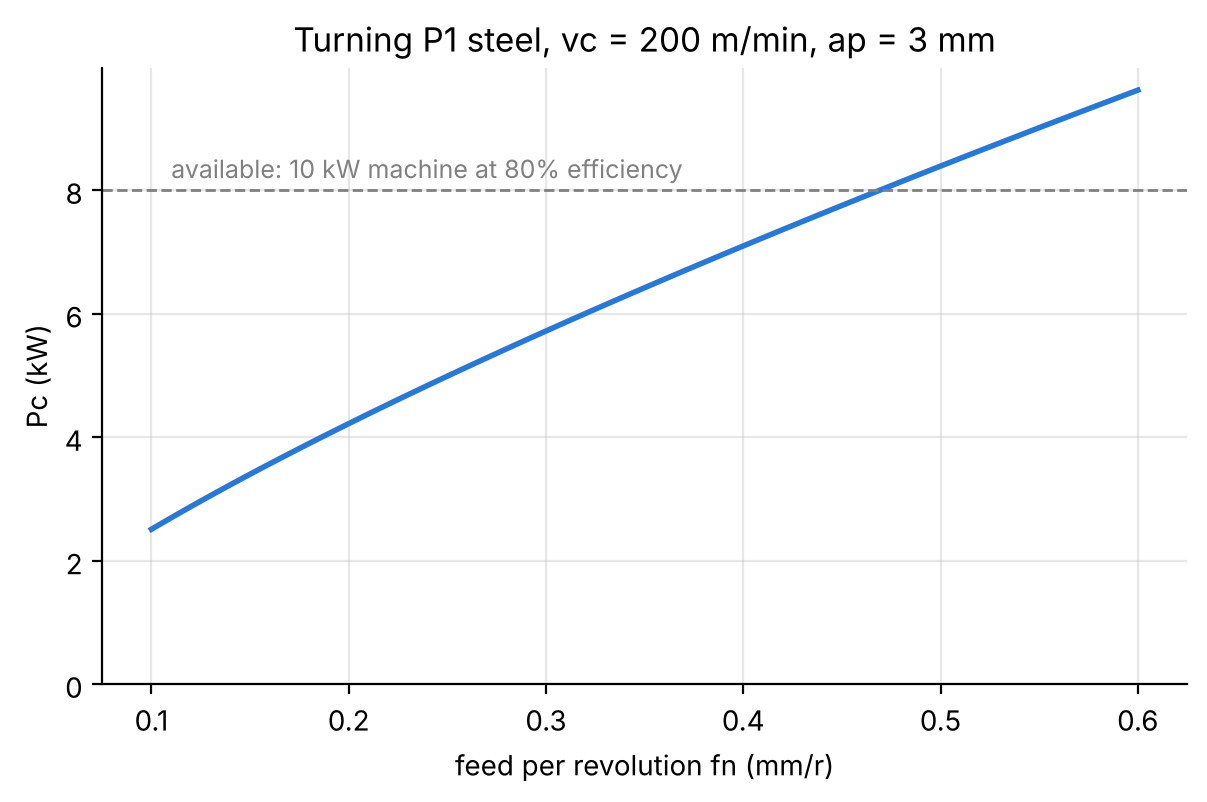

In [6]:
fns = np.linspace(0.1, 0.6, 100)
P = [turning.net_power(vc, ap, f, material.specific_cutting_force(kc1, turning.chip_thickness(f, kr), mc, gamma0))
     for f in fns]
fig, ax = plt.subplots()
ax.plot(fns, P, color=COLORS[0], label="net power Pc")
ax.axhline(10 * 0.8, color="gray", linestyle="--", linewidth=1)
ax.text(0.11, 10 * 0.8 + 0.2, "available: 10 kW machine at 80% efficiency", color="gray", fontsize=9)
ax.set_xlabel("feed per revolution fn (mm/r)")
ax.set_ylabel("Pc (kW)")
ax.set_title("Turning P1 steel, vc = 200 m/min, ap = 3 mm")
ax.set_ylim(bottom=0)
plt.show()

### Turning exercises

**T1.** A Ø80 mm bar is to be turned at $v_c = 250$ m/min. What spindle speed (rpm) should be programmed?

In [7]:
T1_n = ...  # your code here
check("T1_n", T1_n)

[ ] T1_n: not answered yet.


False

**T2.** Unalloyed steel (P1), $D_m = 120$ mm, $v_c = 180$ m/min, $f_n = 0.35$ mm/r, $a_p = 4$ mm, $\kappa_r = 95°$, $\gamma_0 = 6°$. Calculate the chip thickness $h_m$, the specific cutting force $k_c$ and the net power $P_c$.

In [8]:
kc1, mc = material.get("P1 unalloyed steel")
T2_hm = ...  # your code here
T2_kc = ...  # your code here
T2_Pc = ...  # your code here
check("T2_hm", T2_hm); check("T2_kc", T2_kc); check("T2_Pc", T2_Pc)

[ ] T2_hm: not answered yet.
[ ] T2_kc: not answered yet.
[ ] T2_Pc: not answered yet.


False

**T3.** A lathe has a 15 kW spindle motor with 80 % drive efficiency. You are roughing P1 steel at $v_c = 200$ m/min, $f_n = 0.4$ mm/r, $\kappa_r = 95°$, $\gamma_0 = 6°$. What is the largest depth of cut $a_p$ the machine can take? (Hint: rearrange the power formula for $a_p$. Note that $k_c$ does not depend on $a_p$.)

In [9]:
hm = ...  # your code here
kc = ...  # your code here
T3_ap = ...  # your code here
check("T3_ap", T3_ap)

[ ] T3_ap: not answered yet.


False

**T4.** How long (in minutes) does one pass of 200 mm take on a Ø60 mm shaft at $v_c = 220$ m/min and $f_n = 0.25$ mm/r?

In [10]:
n = ...  # your code here
T4_Tc = ...  # your code here
check("T4_Tc", T4_Tc)

[ ] T4_Tc: not answered yet.


False

**T5.** Surface finish. The theoretical profile left by a round nose of radius $r_\varepsilon$ gives

$$R_{max} = \frac{f_n^2}{8\, r_\varepsilon} \cdot 1000\ \mu\text{m} \qquad R_a \approx \frac{f_n^2}{18\sqrt{3}\, r_\varepsilon} \cdot 1000\ \mu\text{m} \approx \frac{R_{max}}{4}$$

The drawing asks for $R_a \le 1.6\ \mu$m. What is the largest feed you can use with a 0.8 mm nose radius (`T5_fn08`)? With a 1.2 mm nose radius (`T5_fn12`)? What does this tell you about choosing inserts for finishing?

In [11]:
T5_fn08 = ...  # your code here
T5_fn12 = ...  # your code here
check("T5_fn08", T5_fn08); check("T5_fn12", T5_fn12)

[ ] T5_fn08: not answered yet.
[ ] T5_fn12: not answered yet.


False

## 3. Milling

### 3.1 Speed and feed

$$v_c = \frac{\pi \cdot D_{cap} \cdot n}{1000} \qquad v_f = f_z \cdot n \cdot z_c \qquad f_n = \frac{v_f}{n} \qquad Q = \frac{a_p \cdot a_e \cdot v_f}{1000}$$

### 3.2 Chip thickness and chip thinning

In milling, each tooth cuts a comma-shaped chip whose thickness changes as the tooth sweeps through the cut. How thick it gets depends on the radial engagement $a_e / D_{cap}$.

**Side (shoulder) milling**, cutter on one side of the workpiece:

$$h_m = \frac{360 \cdot a_e \cdot f_z \cdot \sin\kappa_r}{\pi \cdot D_{cap} \cdot \arccos\left(1 - \frac{2 a_e}{D_{cap}}\right)} \qquad h_{ex} = f_z \sin\kappa_r \cdot 2\sqrt{\frac{a_e}{D_{cap}} - \left(\frac{a_e}{D_{cap}}\right)^2}\quad (a_e < D_{cap}/2)$$

For small engagements ($a_e / D_{cap} < 0.1$) this simplifies to $h_m \approx f_z \sin\kappa_r \sqrt{a_e / D_{cap}}$.

**Face milling, workpiece centred** under the cutter:

$$h_m = \frac{180 \cdot a_e \cdot f_z \cdot \sin\kappa_r}{\pi \cdot D_{cap} \cdot \arcsin\left(\frac{a_e}{D_{cap}}\right)} \qquad h_{ex} = f_z \sin\kappa_r$$

The arccos and arcsin are in degrees. When $a_e$ is small in side milling, the chip is much thinner than $f_z$. This is **chip thinning**: to keep the edge cutting properly, the feed per tooth must be raised.

### 3.3 Power and torque

$$P_c = \frac{a_p \cdot a_e \cdot v_f \cdot k_c}{60 \cdot 10^6}\ \text{kW} \qquad M_c = \frac{P_c \cdot 30 \cdot 10^3}{\pi \cdot n}\ \text{Nm} \qquad T_c = \frac{l_m}{v_f}$$

with $k_c$ evaluated at the average chip thickness $h_m$.

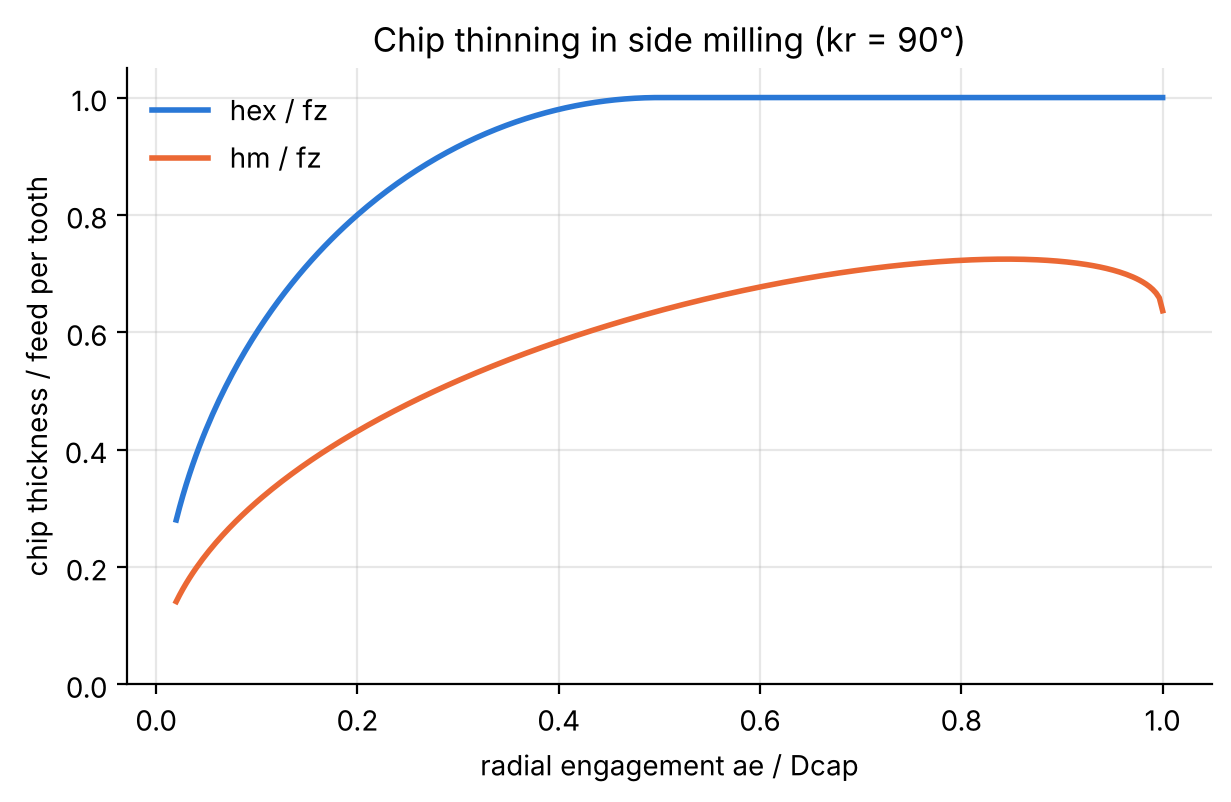

In [12]:
r = np.linspace(0.02, 1.0, 300)
fig, ax = plt.subplots()
ax.plot(r, [milling.max_chip_thickness_side(1, x, 1) for x in r], color=COLORS[0], label="hex / fz")
ax.plot(r, [milling.avg_chip_thickness_side(1, x, 1) for x in r], color=COLORS[1], label="hm / fz")
ax.set_xlabel("radial engagement ae / Dcap")
ax.set_ylabel("chip thickness / feed per tooth")
ax.set_title("Chip thinning in side milling (kr = 90°)")
ax.set_ylim(0, 1.05)
ax.legend(frameon=False)
plt.show()

**Worked example.** Side milling with a Ø40 mm, 4-tooth end mill, $a_e = 4$ mm, $a_p = 10$ mm, $f_z = 0.1$ mm, $v_c = 200$ m/min, $\kappa_r = 90°$, low-alloy steel (P2), $\gamma_0 = 10°$.

In [13]:
kc1, mc = material.get("P2 low-alloy steel")
Dcap, zc, ae, ap, fz, vc, kr = 40, 4, 4, 10, 0.1, 200, 90

n   = milling.spindle_speed(vc, Dcap)
vf  = milling.table_feed(fz, n, zc)
hm  = milling.avg_chip_thickness_side(fz, ae, Dcap, kr)
hex_ = milling.max_chip_thickness_side(fz, ae, Dcap, kr)
kc  = material.specific_cutting_force(kc1, hm, mc, gamma0=10)
Pc  = milling.net_power(ap, ae, vf, kc)
Mc  = milling.torque(Pc, n)

print(f"n   = {n:7.0f} rpm      vf = {vf:6.0f} mm/min")
print(f"hm  = {hm:7.4f} mm     hex = {hex_:6.4f} mm   (fz = {fz} mm)")
print(f"kc  = {kc:7.0f} N/mm^2")
print(f"Pc  = {Pc:7.2f} kW       Mc = {Mc:6.1f} Nm")

n   =    1592 rpm      vf =    637 mm/min
hm  =  0.0311 mm     hex = 0.0600 mm   (fz = 0.1 mm)
kc  =    3644 N/mm^2
Pc  =    1.55 kW       Mc =    9.3 Nm


### Milling exercises

**M1.** A Ø80 mm face mill with 6 effective teeth runs at $v_c = 220$ m/min and $f_z = 0.15$ mm. Find the spindle speed $n$ and table feed $v_f$.

In [14]:
M1_n = ...  # your code here
M1_vf = ...  # your code here
check("M1_n", M1_n); check("M1_vf", M1_vf)

[ ] M1_n: not answered yet.
[ ] M1_vf: not answered yet.


False

**M2.** Side milling with a Ø40 mm end mill, $a_e = 8$ mm, $\kappa_r = 90°$, $f_z = 0.1$ mm.

(a) Calculate $h_m$ and $h_{ex}$.
(b) The insert is designed for $h_{ex} = 0.1$ mm. What feed per tooth $f_z$ do you need to reach it?

In [15]:
M2_hm = ...  # your code here
M2_hex = ...  # your code here
M2_fz = ...  # your code here
check("M2_hm", M2_hm); check("M2_hex", M2_hex); check("M2_fz", M2_fz)

[ ] M2_hm: not answered yet.
[ ] M2_hex: not answered yet.
[ ] M2_fz: not answered yet.


False

**M3.** Face milling a 100 mm wide grey cast iron (K1) block, centred under a Ø125 mm cutter with 8 teeth and $\kappa_r = 45°$. $a_p = 3$ mm, $v_c = 250$ m/min, $f_z = 0.2$ mm, $\gamma_0 = 0°$. Calculate $h_m$, $k_c$, $Q$, $P_c$ and $M_c$.

In [16]:
kc1, mc = material.get("K1 grey cast iron")
M3_hm = ...  # your code here
M3_kc = ...  # your code here
n = ...  # your code here
vf = ...  # your code here
M3_Q = ...  # your code here
M3_Pc = ...  # your code here
M3_Mc = ...  # your code here
for k, v in [("M3_hm", M3_hm), ("M3_kc", M3_kc), ("M3_Q", M3_Q), ("M3_Pc", M3_Pc), ("M3_Mc", M3_Mc)]:
    check(k, v)

[ ] M3_hm: not answered yet.
[ ] M3_kc: not answered yet.
[ ] M3_Q: not answered yet.
[ ] M3_Pc: not answered yet.
[ ] M3_Mc: not answered yet.


## 4. Drilling

$$v_c = \frac{\pi \cdot D_c \cdot n}{1000} \qquad v_f = f_n \cdot n \qquad Q = \frac{v_c \cdot D_c \cdot f_n}{4}\ \text{cm}^3/\text{min}$$

A drill has two cutting edges that share the feed, so each edge cuts a chip of thickness

$$h_{ex} = \frac{f_n}{2} \sin\kappa_r$$

where $\kappa_r$ is half the point angle (70° for a 140° point). Power, torque and feed force:

$$P_c = \frac{f_n \cdot v_c \cdot D_c \cdot k_c}{240 \cdot 10^3}\ \text{kW} \qquad M_c = \frac{P_c \cdot 30 \cdot 10^3}{\pi \cdot n}\ \text{Nm} \qquad F_f \approx 0.5 \cdot k_c \cdot \frac{D_c}{2} \cdot f_n \cdot \sin\kappa_r\ \text{N}$$

**Where does 240 come from?** Each edge removes an area $\frac{D_c}{2}\cdot\frac{f_n}{2}$, and the cutting force on it acts at about $D_c/4$ from the centre. The tests in `tests/test_drilling_and_tool_life.py` check this derivation numerically.

### Drilling exercise

**D1.** A Ø20 mm drill with a 140° point drills a 60 mm deep hole in low-alloy steel (P2) at $v_c = 120$ m/min and $f_n = 0.25$ mm/r, with $\gamma_0 = 0°$. Calculate $n$, $v_f$, $h_m$, $k_c$, $P_c$, $M_c$, $F_f$ and the machining time $T_c$.

In [17]:
kc1, mc = material.get("P2 low-alloy steel")
D1_n = ...  # your code here
D1_vf = ...  # your code here
D1_hm = ...  # your code here
D1_kc = ...  # your code here
D1_Pc = ...  # your code here
D1_Mc = ...  # your code here
D1_Ff = ...  # your code here
D1_Tc = ...  # your code here
for k in ["D1_n", "D1_vf", "D1_hm", "D1_kc", "D1_Pc", "D1_Mc", "D1_Ff", "D1_Tc"]:
    check(k, globals()[k])

[ ] D1_n: not answered yet.
[ ] D1_vf: not answered yet.
[ ] D1_hm: not answered yet.
[ ] D1_kc: not answered yet.
[ ] D1_Pc: not answered yet.
[ ] D1_Mc: not answered yet.
[ ] D1_Ff: not answered yet.
[ ] D1_Tc: not answered yet.


## 5. Tool life and machining economy

Higher cutting speed removes metal faster but wears the edge out sooner. Taylor's equation captures this trade-off:

$$v_c \cdot T^{\,n} = C \qquad\Longleftrightarrow\qquad T = \left(\frac{C}{v_c}\right)^{1/n}$$

$T$ is tool life in minutes, $n$ is the Taylor exponent (about 0.2 to 0.4 for carbide) and $C$ is the speed that gives one minute of tool life. Two tests at different speeds are enough to find both constants:

$$n = \frac{\ln(v_{c1}/v_{c2})}{\ln(T_2/T_1)} \qquad C = v_{c1}\, T_1^{\,n}$$

**Economy.** Running faster saves machine time but costs more edges and tool changes. The tool life that minimises cost per part is

$$T_{econ} = \left(\frac{1}{n} - 1\right)\left(t_{ct} + \frac{C_t}{M}\right)$$

where $t_{ct}$ is the time to change an edge (min), $C_t$ the cost of one edge and $M$ the machine and operator cost per minute. The tool life for maximum output is $T_{prod} = (1/n - 1)\, t_{ct}$, which is always shorter.

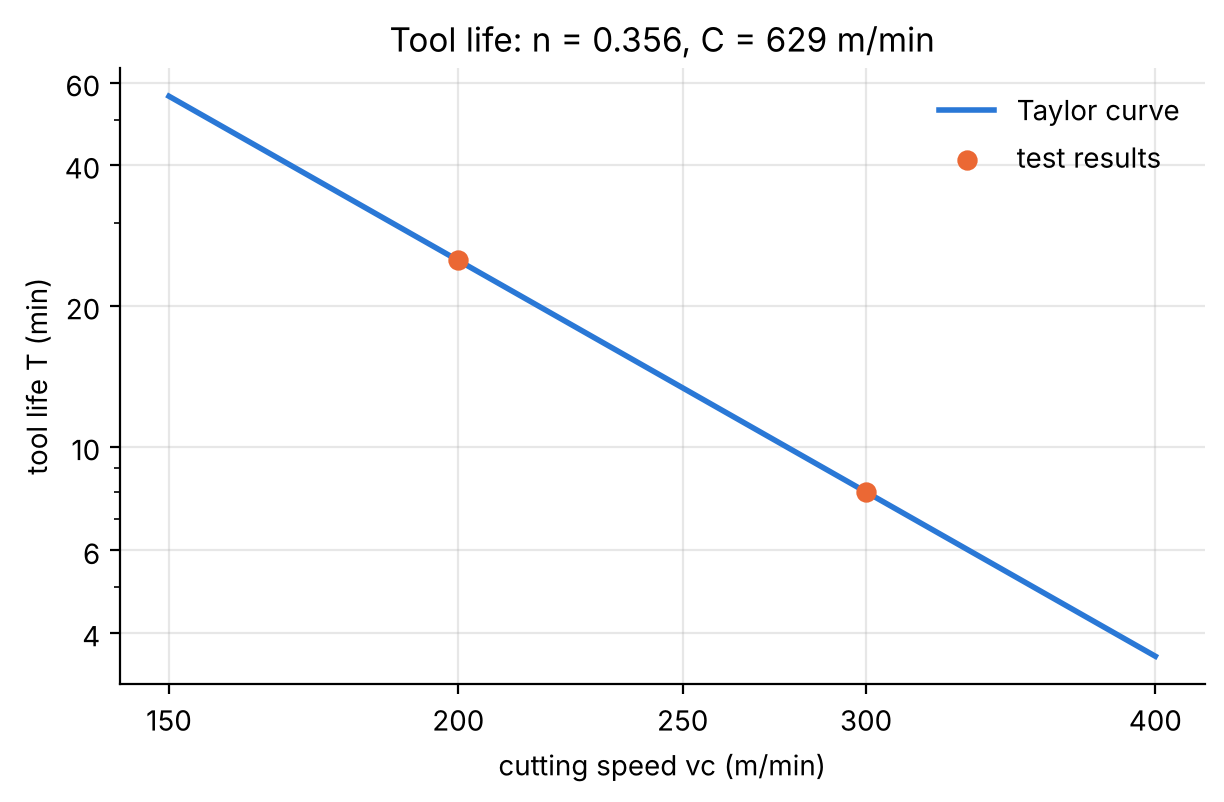

In [18]:
n_t, C = tool_life.fit_taylor(200, 25, 300, 8)
v = np.linspace(150, 400, 200)
fig, ax = plt.subplots()
ax.plot(v, [tool_life.tool_life(x, C, n_t) for x in v], color=COLORS[0], label="Taylor curve")
ax.scatter([200, 300], [25, 8], color=COLORS[1], s=40, zorder=3, label="test results")
ax.set_xscale("log"); ax.set_yscale("log")
from matplotlib.ticker import ScalarFormatter, NullFormatter
ax.set_xticks([150, 200, 250, 300, 400]); ax.set_yticks([4, 6, 10, 20, 40, 60])
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(ScalarFormatter()); axis.set_minor_formatter(NullFormatter())
ax.set_xlabel("cutting speed vc (m/min)")
ax.set_ylabel("tool life T (min)")
ax.set_title(f"Tool life: n = {n_t:.3f}, C = {C:.0f} m/min")
ax.legend(frameon=False)
plt.show()

### Tool life exercises

**L1.** Two tool life tests on the same insert and material: 200 m/min gave 25 min, 300 m/min gave 8 min. Find the Taylor constants $n$ and $C$. Then predict the tool life at 250 m/min (`L1_T250`), and the speed that gives 15 min of tool life (`L1_v15`).

In [19]:
L1_n, L1_C = ..., ...  # your code here
L1_T250 = ...  # your code here
L1_v15 = ...  # your code here
for k in ["L1_n", "L1_C", "L1_T250", "L1_v15"]:
    check(k, globals()[k])

[ ] L1_n: not answered yet.
[ ] L1_C: not answered yet.
[ ] L1_T250: not answered yet.
[ ] L1_v15: not answered yet.


**L2.** Using the constants from L1: an edge change takes 2 min, one edge costs 4 €, and the machine with its operator costs 1.5 €/min. Find the economic tool life $T_{econ}$ and the corresponding cutting speed.

In [20]:
L2_T = ...  # your code here
L2_vc = ...  # your code here
check("L2_T", L2_T); check("L2_vc", L2_vc)

[ ] L2_T: not answered yet.
[ ] L2_vc: not answered yet.


False

## 6. Capstone: planning a two-operation part

A shaft in low-alloy steel (P2) needs two operations on an 11 kW machine with 85 % drive efficiency:

1. **Turning:** one roughing pass along 150 mm at $D_m = 60$ mm, $v_c = 200$ m/min, $f_n = 0.3$ mm/r, $a_p = 3$ mm, $\kappa_r = 95°$, $\gamma_0 = 6°$.
2. **Drilling:** a Ø12 mm hole, 40 mm deep plus 2 mm approach, at $v_c = 100$ m/min, $f_n = 0.2$ mm/r, 140° point, $\gamma_0 = 0°$.

Find:

* `C1_Tc_total`: the total cutting time of both operations (min).
* `C1_P_spindle_max`: the largest spindle power needed by either operation, including efficiency (kW). Can the machine do both?

Then explore: what turning feed would use the machine's full power? How much time would that save?

In [21]:
kc1, mc = material.get("P2 low-alloy steel")

# Turning
n_t = ...  # your code here
kc_t = ...  # your code here
Pc_t = ...  # your code here
Tc_t = ...  # your code here

# Drilling
n_d = ...  # your code here
kc_d = ...  # your code here
Pc_d = ...  # your code here
Tc_d = ...  # your code here

C1_Tc_total = ...  # your code here
C1_P_spindle_max = ...  # your code here
check("C1_Tc_total", C1_Tc_total); check("C1_P_spindle_max", C1_P_spindle_max)

[ ] C1_Tc_total: not answered yet.
[ ] C1_P_spindle_max: not answered yet.


False

## Going further

* Replace the values in `material.MATERIALS` with those from the handbook's material table and rerun the notebook.
* Read `tests/` to see how each formula was verified, then write a test for a formula of your own.
* Combine tool life and power: for the capstone part, find the cutting speed that minimises cost per part with `tool_life.cost_per_part`, and check that the machine has enough power at that speed.